# Phase 5 — Simulating the pair

**What the brief asks.** Real history is one path. Generate other plausible **joint** paths of the two
stocks (keeping how they move together), re-run the Phase 2 signal on each, and report how its
performance varies: the best evidence for or against the relationship being "a real, robust effect rather
than a fit to one specific historical accident".

**Result**
- **Method: joint block bootstrap** (the brief's "simple" option): 1,000 synthetic 19-year paths of KO and
  PEP built from 10-day blocks of real in-sample days, the same days for both stocks.
- **The performance is not consistent.** With the frozen rules, the Sharpe ratio on the paths has a median
  of 0.17 and 90% of paths fall between −0.23 and +0.53; one path in four loses money. The real in-sample
  Sharpe (0.35) sits at the **80th percentile**: a good draw, not an exceptional one.
- **The 0.35 never stands out**, in any of the worlds I simulated: not against pure day-by-day noise (92nd
  percentile), not once the Phase 2 grid search is repeated on every path (67th), not against a world in
  which the long-run relationship is real by construction (Ornstein-Uhlenbeck check, 80th).
- What the signal does earn on the paths comes from **short-term pull-backs of the spread, over days to a few
  weeks**: the longer the blocks keep real days together, the higher the Sharpe (median 0.02 with 1-day
  blocks, 0.27 with 20-day blocks). The long-run tie between the two stocks adds nothing measurable.
- **Answer to the brief: evidence against a robust effect.** Nineteen years of history cannot tell this
  strategy's in-sample result apart from luck, which is consistent with the out-of-sample loss of Phase 2.

Everything here uses **in-sample data only (2000–2018)**: the out-of-sample years are never resampled. Terms:
README glossary.

## 1. Method, and why I added a second one

**Chosen method: joint block bootstrap.** I cut the real in-sample history into blocks of consecutive
trading days, draw blocks at random (the same block can come back: "with replacement") and glue them into a
new 19-year history. Each block is taken from **both stocks at once**, so on every synthetic day KO and PEP
move as they really did together on some real day. It needs no model: the paths are made of real days.

**Why not only the "medium" option (an Ornstein-Uhlenbeck spread).** That option assumes the spread is
pulled back to a long-run average, and estimates the pull from the real spread. Phase 2 did not establish
that pull (Engle-Granger p = 0.12, half-life 192 days): simulating from it would put into the paths the very
thing I am trying to test. So it cannot be my main evidence.

**Why I still ran it, as a declared extra check (the brief says "pick one").** The two methods describe two
opposite worlds:
- **bootstrap: no long-run relationship.** Blocks of 10 days keep the daily co-movement and anything that
  happens within two weeks, but they are drawn independently, so a pull-back over months cannot survive;
- **OU: the relationship is real**, with exactly the strength I measured.

If the real Sharpe looks ordinary in **both** worlds, the data cannot tell them apart, and the in-sample
result says nothing about whether the relationship is real. The OU is one extra configuration in the trial
log, reported separately from the chosen method.

**Choices, fixed before computing anything** (with the prediction: centred between 0 and 0.1, real 0.35
around the 85th–90th percentile, lower once the selection is repeated; the centre turned out higher, section 4):

| Choice | Value | Why |
|---|---|---|
| Days resampled | In-sample only, 2000-01-03 to 2018-12-31 (`as_of`) | The out-of-sample was used once in Phase 2 and stays untouched; the 0.35 to compare is in-sample |
| Path | 4,779 days, the in-sample calendar, real prices on day one | Same length and evaluation period as Phase 2 |
| Block length | 10 days; 5 and 20 as sensitivity | The middle and the two ends of the brief's 5–20 |
| Paths, seed | 1,000 per configuration, seed 20261010 | Stable 5th and 95th percentiles; reproducible |
| Hedge ratio | Re-estimated by OLS on each path | Phase 2 estimated it on the data it traded; I repeat the procedure, since the number 0.388 means nothing on other prices |
| Rules | Frozen: entry 1.5, window 60, exit 0, evaluated from the 250th day | The strategy of Phase 2, unchanged |
| Selection | Second analysis: the 25-cell grid and the stable-zone rule re-run on each path | The real 0.35 won a selection among 25 cells; the fair comparison is winner against winner |

In [1]:
import logging
import pickle

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display

from pairs.config import PAIR, PHASE2_STRATEGY, SIGNAL_GRID, Settings
from pairs.data import load_pair_prices
from pairs.logging_setup import configure_logging
from pairs.plots import finish_figure, save_figure
from pairs.simulate import (
    fit_ou,
    frozen_rules_on_path,
    selected_rules_on_path,
    simulate_joint_prices,
    simulate_ou,
    spread_pnl_sharpe,
)
from pairs.spread import build_spread
from pairs.trials import count_trials, log_trial

configure_logging(logging.WARNING)
pio.renderers.default = "plotly_mimetype+png"
settings = Settings.from_env()
figures_dir = settings.results_dir / "figures"
trials_db = settings.results_dir / "trials.sqlite"
A, B, S, AS_OF = PAIR.ticker_a, PAIR.ticker_b, PHASE2_STRATEGY, PAIR.in_sample_end
SOURCE = (
    "Source: Yahoo Finance adjusted close, in-sample 2000-2018; 1,000 simulated paths per case."
)

BLOCKS = (5, 10, 20)  # trading days; 10 is the main case
EXPLORATORY_BLOCK = 1  # added after seeing the results (section 4)
MAIN_BLOCK = 10
N_PATHS = 1000
SEED = 20261010
START = max(SIGNAL_GRID.windows) - 1  # first evaluated day, as in Phase 2 (the 250th)

prices = load_pair_prices(PAIR, settings.data_dir, AS_OF)  # in-sample only
real = frozen_rules_on_path(prices, A, B, S.entry, S.window, START, AS_OF)
print(f"Real in-sample: Sharpe {real['sharpe']:.3f}, beta {real['beta']:.4f}, {len(prices)} days")

Real in-sample: Sharpe 0.351, beta 0.3884, 4779 days


The line above re-runs Phase 2 on the real data with the same function used on every path: same
Sharpe (0.35) and hedge ratio (0.388) as in Phase 2, so the paths and history are measured identically.

The simulation takes about four minutes, so its result is saved once as a checkpoint
(`data/phase5_simulation.pkl`) and re-read; deleting the file recomputes it with the same seed.

In [2]:
def simulate_all() -> dict[str, pd.DataFrame]:
    out = {}
    for block in (EXPLORATORY_BLOCK, *BLOCKS):
        rng = np.random.default_rng([SEED, block])
        rows = []
        for _ in range(N_PATHS):
            path = simulate_joint_prices(prices, block, rng, AS_OF)
            row = frozen_rules_on_path(path, A, B, S.entry, S.window, START, AS_OF)
            ret = path.pct_change().iloc[1:]
            row["corr"] = float(ret[A].corr(ret[B]))
            if block == MAIN_BLOCK:
                spread = build_spread(path, A, B, row["beta"])
                row["dollar_sharpe"] = spread_pnl_sharpe(spread, S.entry, S.window, START)
                sel = selected_rules_on_path(path, A, B, SIGNAL_GRID, AS_OF)
                row.update({f"selected_{k}": v for k, v in sel.items()})
            rows.append(row)
        out[f"bootstrap_{block}"] = pd.DataFrame(rows)
    ou_fit = fit_ou(build_spread(prices, A, B, S.beta), AS_OF)
    rng = np.random.default_rng([SEED, 0])
    first_value = float(build_spread(prices, A, B, S.beta).iloc[0])
    out["ou"] = pd.DataFrame(
        {
            "dollar_sharpe": [
                spread_pnl_sharpe(
                    pd.Series(
                        simulate_ou(ou_fit, first_value, len(prices), rng), index=prices.index
                    ),
                    S.entry,
                    S.window,
                    START,
                )
                for _ in range(N_PATHS)
            ]
        }
    )
    return out


checkpoint = settings.data_dir / "phase5_simulation.pkl"
if checkpoint.exists():
    with checkpoint.open("rb") as fh:
        sims = pickle.load(fh)
else:
    sims = simulate_all()
    with checkpoint.open("wb") as fh:
        pickle.dump(sims, fh)
main = sims[f"bootstrap_{MAIN_BLOCK}"]
assert all(len(v) == N_PATHS for v in sims.values())

## 2. Do the synthetic paths look like KO and PEP?

A bootstrap is only useful if each path is a believable joint history. Three checks on the 1,000 paths
with 10-day blocks, against the real in-sample, then three paths drawn as an example.

In [3]:
ret = prices.pct_change().iloc[1:]
checks = pd.DataFrame(
    {
        "real": [ret[A].corr(ret[B]), real["beta"], real["n_trades"]],
        "paths: median": [main["corr"].median(), main["beta"].median(), main["n_trades"].median()],
        "paths: 5%": [
            main["corr"].quantile(0.05),
            main["beta"].quantile(0.05),
            main["n_trades"].quantile(0.05),
        ],
        "paths: 95%": [
            main["corr"].quantile(0.95),
            main["beta"].quantile(0.95),
            main["n_trades"].quantile(0.95),
        ],
    },
    index=[
        "Daily return correlation KO-PEP",
        "Hedge ratio (OLS on the path)",
        "Trades of the frozen rules",
    ],
)
checks.round(2)

,real,paths: median,paths: 5%,paths: 95%
Daily return correlation KO-PEP,0.55,0.55,0.51,0.60
Hedge ratio (OLS on the path),0.39,0.30,-0.02,1.38
Trades of the frozen rules,94.00,98.00,85.00,112.00


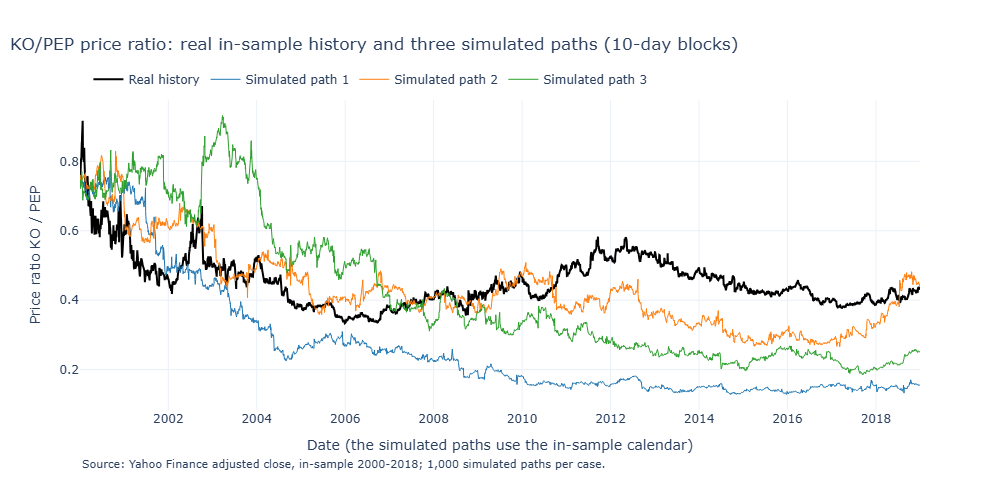

In [4]:
example_rng = np.random.default_rng([SEED, 99])  # separate stream: only for this picture
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=prices.index,
        y=prices[A] / prices[B],
        name="Real history",
        line={"color": "black", "width": 2},
    )
)
for k, color in enumerate(["#1f77b4", "#ff7f0e", "#2ca02c"], start=1):
    path = simulate_joint_prices(prices, MAIN_BLOCK, example_rng, AS_OF)
    fig.add_trace(
        go.Scatter(
            x=path.index,
            y=path[A] / path[B],
            name=f"Simulated path {k}",
            line={"color": color, "width": 1},
        )
    )
finish_figure(
    fig,
    "KO/PEP price ratio: real in-sample history and three simulated paths (10-day blocks)",
    "Date (the simulated paths use the in-sample calendar)",
    "Price ratio KO / PEP",
    SOURCE,
)
save_figure(fig, "05_example_paths", figures_dir)
fig.show()

**Reading.** The co-movement survives: on the paths the daily correlation of the two stocks stays between
0.50 and 0.60, around the real 0.55, and the frozen rules trade about as often as in reality (median 98
trades against 94). What does **not** survive is the long-run tie: the price ratio wanders off in any
direction (the real ratio went from 0.73 in January 2000 to a low of 0.33 in 2005 and 0.43 at the end of 2018;
the simulated ones go wherever their blocks take them), and
the hedge ratio re-estimated on each path ranges from about 0 to 1.4 instead of staying near 0.39. That is
the point of the test: these are histories in which KO and PEP move together day by day **without** being
tied together over years.

## 3. Main result: the Phase 2 signal on 1,000 paths

How to read the chart: each bar counts the paths whose Sharpe ratio fell in that range; the black line is
the real in-sample Sharpe. If the line sat far to the right of almost all bars, the real history would hold
something the paths do not.

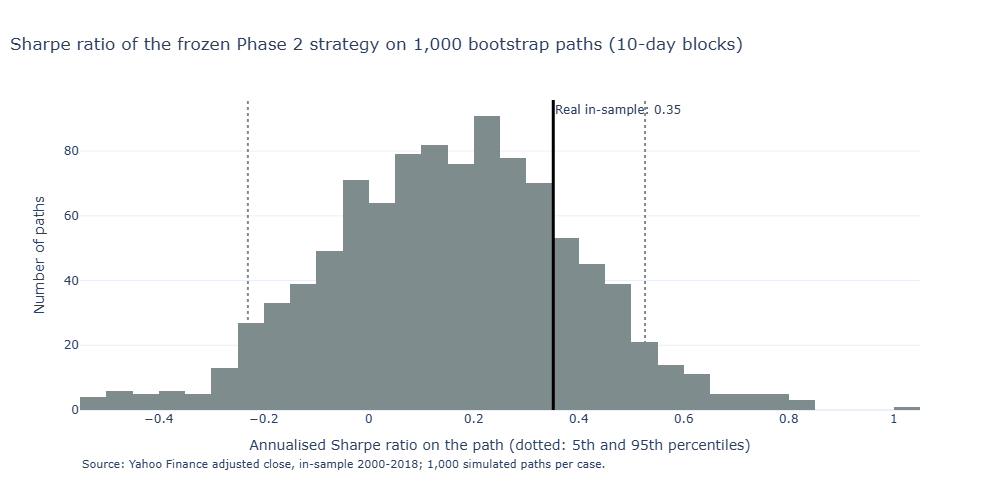

paths              1000.000
median                0.165
p05                  -0.230
p95                   0.526
share_positive        0.742
real_value            0.351
real_percentile       0.799
dtype: float64

In [5]:
def describe(values: pd.Series, real_value: float) -> dict[str, float]:
    v = values.dropna()
    return {
        "paths": float(len(v)),
        "median": float(v.median()),
        "p05": float(v.quantile(0.05)),
        "p95": float(v.quantile(0.95)),
        "share_positive": float((v > 0).mean()),
        "real_value": real_value,
        "real_percentile": float((v < real_value).mean()),
    }


main_stats = describe(main["sharpe"], real["sharpe"])
fig = go.Figure(
    go.Histogram(x=main["sharpe"], nbinsx=50, marker_color="#7f8c8d", name="Simulated paths")
)
fig.add_vline(x=real["sharpe"], line_color="black", line_width=3)
fig.add_annotation(
    x=real["sharpe"],
    y=1,
    yref="paper",
    text=f"Real in-sample: {real['sharpe']:.2f}",
    showarrow=False,
    xanchor="left",
    yanchor="top",
)
for q in ("p05", "p95"):
    fig.add_vline(x=main_stats[q], line_dash="dot", line_color="#7f8c8d")
finish_figure(
    fig,
    "Sharpe ratio of the frozen Phase 2 strategy on 1,000 bootstrap paths (10-day blocks)",
    "Annualised Sharpe ratio on the path (dotted: 5th and 95th percentiles)",
    "Number of paths",
    SOURCE,
)
save_figure(fig, "05_bootstrap_sharpe", figures_dir)
fig.show()
pd.Series(main_stats).round(3)

**Reading.** If history had been reshuffled in two-week pieces, the same strategy would have produced
almost anything between a Sharpe of −0.23 and +0.53 (90% of paths), with a median of 0.17; 26% of paths lose
money. The real 0.35 beats 80% of the paths: history was kind to the strategy, but one path in five did
better by pure reshuffling. With the usual 5% standard, the real result is **not** distinguishable from what
reshuffled histories produce.

## 4. Block length, and where the positive median comes from

My prediction put the centre of the paths near zero; it came out at 0.17. Two explanations were possible,
so I added one **exploratory** configuration after seeing the results (logged separately in the trial log):
blocks of **one day**, which keep only the same-day co-movement and nothing of what happens over the
following days.
1. If the positive centre came from estimating the hedge ratio on the same path it is traded on (a known
   flattering effect, also present in the real 0.35), it would remain with 1-day blocks.
2. If it came from short-term pull-backs of the spread kept inside each block, it would vanish.

In [6]:
summary = {
    f"Bootstrap, {b}-day blocks{' (exploratory)' if b == EXPLORATORY_BLOCK else ''}": describe(
        sims[f"bootstrap_{b}"]["sharpe"], real["sharpe"]
    )
    for b in (EXPLORATORY_BLOCK, *BLOCKS)
}
blocks_table = pd.DataFrame(summary).T
spread_real = build_spread(prices, A, B, S.beta)
daily_var = spread_real.diff().var()
variance_ratio = pd.Series(
    {h: spread_real.diff(h).var() / (h * daily_var) for h in (5, 10, 20, 60, 120)},
    name="real spread",
)
display(blocks_table[["median", "p05", "p95", "share_positive", "real_percentile"]].round(3))
variance_ratio.round(2).to_frame().T

,median,p05,p95,share_positive,real_percentile
"Bootstrap, 1-day blocks (exploratory)",0.017,-0.359,0.401,0.523,0.919
"Bootstrap, 5-day blocks",0.100,-0.262,0.447,0.658,0.871
"Bootstrap, 10-day blocks",0.165,-0.230,0.526,0.742,0.799
"Bootstrap, 20-day blocks",0.268,-0.093,0.625,0.887,0.643


,5,10,20,60,120
real spread,0.92,0.87,0.76,0.61,0.46


**Reading.** The median Sharpe climbs with the block length: 0.02 with 1-day blocks, 0.10 with 5, 0.17 with
10, 0.27 with 20. So the hedge-ratio effect (explanation 1) is negligible, and what the signal earns comes from
something that only longer blocks preserve. The second table shows what that is. A **variance ratio** compares
how much the spread moves over h days with h times its daily move: 1 for a pure random walk, below 1 when moves
are partly undone later. For the real spread it falls from 0.92 at 5 days to 0.76 at 20 and 0.61 at 60 days:
the spread does pull back, over weeks to months. A 20-day block keeps more of that pull-back than a 5-day
block, so the strategy earns more.

That is the honest description of the edge: **a short-term pull-back of the spread**, real in the data. But even
against the 1-day world, where no pull-back exists, the real 0.35 only reaches the 92nd percentile, below the
usual 95%. Its rank falls as more of the real dynamics is kept (87th, 80th, 64th): the more realistic the
reshuffled histories, the more ordinary the real result looks.

## 5. Accounting for the selection among 25 variants

In Phase 2 the strategy was **chosen**: 25 combinations of threshold and window were backtested and the
pre-registered stable-zone rule picked one. A chosen winner looks better than a single variant fixed in
advance. To compare like with like, on each of the 1,000 paths (10-day blocks) I re-ran the whole Phase 2
procedure, all 25 cells and the same rule, and kept the Sharpe of the cell the rule picks.

In [7]:
selection_stats = describe(main["selected_sharpe"], real["sharpe"])
picked = pd.DataFrame(
    {
        "chosen threshold (share of paths)": main["selected_entry"]
        .value_counts(normalize=True)
        .sort_index(),
        "chosen window (share of paths)": main["selected_window"]
        .value_counts(normalize=True)
        .sort_index(),
    }
)
display(pd.Series(selection_stats).round(3))
picked.round(2)

paths              1000.000
median                0.248
p05                  -0.120
p95                   0.609
share_positive        0.856
real_value            0.351
real_percentile       0.667
dtype: float64

,chosen threshold (share of paths),chosen window (share of paths)
1.5,0.48,NaN
2.0,0.16,NaN
2.5,0.36,NaN
60.0,NaN,0.57
120.0,NaN,0.13
190.0,NaN,0.30


**Reading.** With the selection repeated, the median of the paths rises from 0.17 to 0.25 and 86% of them are
positive: tuning on the data finds something positive almost every time, even in reshuffled histories. The
real 0.35 falls to the **67th percentile**. The rule also picks entry 1.5 and window 60, the cells chosen in
Phase 2, more often than any other (on 48% and 57% of paths): the real choice is the typical choice, not a sign
of a special structure in the real data.

## 6. Extra check: a world in which the relationship is real (Ornstein-Uhlenbeck)

An **Ornstein-Uhlenbeck (OU) process** is a random walk with a spring: every day the spread is pulled back
toward a long-run average by a fixed fraction of its distance from it, plus a random shock. Sampled once a
day it is the regression of today's spread on yesterday's, so I estimate it on the real in-sample spread
(KO − 0.388 × PEP, the Phase 2 hedge ratio) and simulate 1,000 spread paths of the same length.

An OU path gives the spread only, not the two prices, so I cannot compute returns on capital. For a like-for-like
comparison I measure the Sharpe of the **daily dollar profit of holding one unit of the spread**, on the OU
paths, on the bootstrap paths (10-day blocks, each with its own hedge ratio) and on the real history.

In [8]:
ou = fit_ou(spread_real, AS_OF)
real_dollar = spread_pnl_sharpe(spread_real, S.entry, S.window, START)
ou_variance_ratio_60 = (1 - ou.phi**60) / (60 * (1 - ou.phi))  # stationary OU, 60 days
worlds = pd.DataFrame(
    {
        "Bootstrap, 10-day blocks (no long-run tie)": describe(main["dollar_sharpe"], real_dollar),
        "OU (long-run tie, as estimated)": describe(sims["ou"]["dollar_sharpe"], real_dollar),
    }
).T
print(
    f"OU: mean {ou.mu:.2f} $, daily pull {1 - ou.phi:.4f}, half-life {ou.half_life:.0f} days, "
    f"daily shock {ou.sigma:.3f} $; 60-day variance ratio {ou_variance_ratio_60:.2f} "
    f"(real {variance_ratio[60]:.2f})"
)
worlds[["median", "p05", "p95", "share_positive", "real_value", "real_percentile"]].round(3)

OU: mean 2.26 $, daily pull 0.0036, half-life 192 days, daily shock 0.184 $; 60-day variance ratio 0.90 (real 0.61)


,median,p05,p95,share_positive,real_value,real_percentile
"Bootstrap, 10-day blocks (no long-run tie)",0.161,-0.239,0.535,0.734,0.367,0.834
"OU (long-run tie, as estimated)",0.173,-0.205,0.544,0.768,0.367,0.799


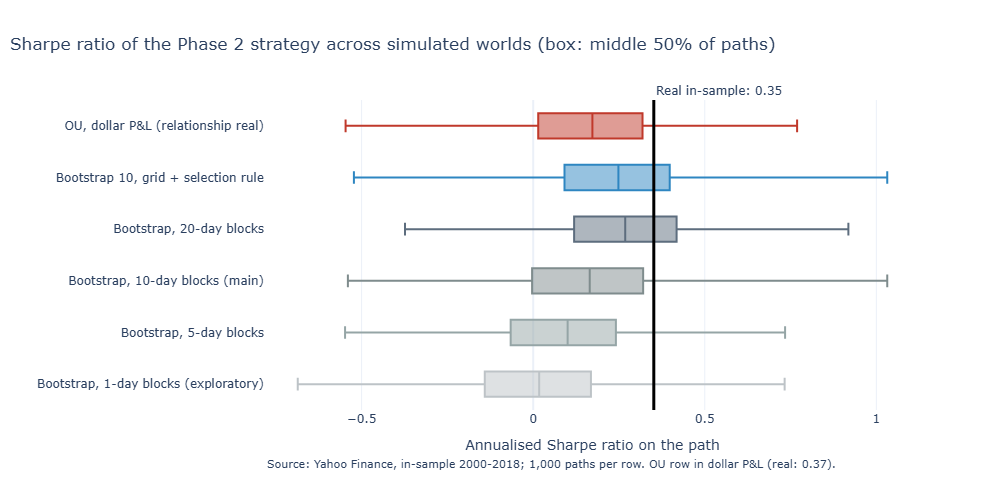

In [9]:
fig = go.Figure()
for name, values, color in [
    (
        "Bootstrap, 1-day blocks (exploratory)",
        sims[f"bootstrap_{EXPLORATORY_BLOCK}"]["sharpe"],
        "#bdc3c7",
    ),
    ("Bootstrap, 5-day blocks", sims["bootstrap_5"]["sharpe"], "#95a5a6"),
    ("Bootstrap, 10-day blocks (main)", main["sharpe"], "#7f8c8d"),
    ("Bootstrap, 20-day blocks", sims["bootstrap_20"]["sharpe"], "#5d6d7e"),
    ("Bootstrap 10, grid + selection rule", main["selected_sharpe"], "#2e86c1"),
    ("OU, dollar P&L (relationship real)", sims["ou"]["dollar_sharpe"], "#c0392b"),
]:
    fig.add_trace(
        go.Box(x=values.dropna(), name=name, marker_color=color, boxpoints=False, orientation="h")
    )
fig.add_vline(x=real["sharpe"], line_color="black", line_width=3)
fig.add_annotation(
    x=real["sharpe"],
    y=1,
    yref="paper",
    text=f"Real in-sample: {real['sharpe']:.2f}",
    showarrow=False,
    xanchor="left",
    yanchor="bottom",
)
finish_figure(
    fig,
    "Sharpe ratio of the Phase 2 strategy across simulated worlds (box: middle 50% of paths)",
    "Annualised Sharpe ratio on the path",
    "",
    "Source: Yahoo Finance, in-sample 2000-2018; 1,000 paths per row. "
    f"OU row in dollar P&L (real: {real_dollar:.2f}).",
)
fig.update_layout(showlegend=False)
save_figure(fig, "05_sharpe_by_world", figures_dir)
fig.show()

**Reading.** In the world where the long-run relationship is real by construction, the strategy does
**no better** than in the world where it does not exist: median 0.17 against 0.16, and the real history (0.37
in this dollar measure) sits at the 80th and 83rd percentile of the two. Two reasons, both in the numbers:
- with a half-life of 192 days the spring is weak: in 60 days, the window of the signal, the OU undoes little of
  a move (variance ratio 0.90), so a 60-day z-score barely sees it;
- the real spread pulls back **faster** over weeks to months than the estimated OU says (variance ratio 0.61 at
  60 days): one spring estimated from daily changes misses the short-term behaviour the strategy actually trades.

So the OU is a poor description of this spread, which confirms that it should not be the main method, and
nineteen years are not enough to distinguish "the relationship is real" from "it is not" through this signal.

## 7. What I conclude, and what I am unsure about

**Answer to the brief: evidence against a real, robust effect.** On reshuffled histories the frozen strategy's
Sharpe spreads from about −0.2 to +0.5; the real 0.35 is a good draw (80th percentile), never an exceptional one
(at most the 92nd percentile, against pure noise), and repeating the Phase 2 tuning on each path makes it more
ordinary (67th). What the strategy earns comes from short-term pull-backs of the spread, not from a long-run
tie between Coca-Cola and PepsiCo. This agrees with Phase 2 (in-sample t = 1.49, out-of-sample loss) and with
Phase 3 (unstable hedge ratio).

**What I am unsure about**
- The bootstrap treats blocks as interchangeable: a 2008 block can follow a 2017 block. Regimes (the
  2000–2005 slide of the ratio, the 2008 crisis) are mixed, which probably widens the distribution.
- The hedge ratio is estimated on the same path it trades, as in Phase 2's in-sample backtest; the 1-day check
  shows this adds little here, but it is an optimistic convention.
- The OU uses one constant pull and normal shocks; section 6 shows it misses the short-term behaviour.
- I do not compare the out-of-sample Sharpe (−0.53) with these distributions: it covers 7.8 years, not 19,
  with a hedge ratio frozen from earlier data, so its natural spread is different.

## Appendix: trial log and checks

Six configurations are added to the trial log: five fixed in advance (three block lengths, the selection
analysis, the OU check) and one exploratory (1-day blocks, decided after seeing the results).

In [10]:
period = (prices.index[START].date(), AS_OF)
base = {"entry": S.entry, "window": S.window, "exit": S.exit, "n_paths": N_PATHS, "seed": SEED}
note_main = "Joint block bootstrap of in-sample daily returns; beta re-estimated on each path."
for b in BLOCKS:
    log_trial(
        trials_db,
        "phase5-simulation",
        f"{A}/{B}",
        "in-sample",
        period,
        {**base, "method": "joint block bootstrap", "block": b, "rules": "frozen"},
        summary[f"Bootstrap, {b}-day blocks"],
        note_main,
    )
log_trial(
    trials_db,
    "phase5-simulation",
    f"{A}/{B}",
    "in-sample",
    period,
    {
        **base,
        "method": "joint block bootstrap",
        "block": MAIN_BLOCK,
        "rules": "grid + stable-zone rule",
    },
    selection_stats,
    note_main + " Sharpe of the cell picked by the Phase 2 rule on each path.",
)
log_trial(
    trials_db,
    "phase5-simulation",
    f"{A}/{B}",
    "in-sample",
    period,
    {**base, "method": "Ornstein-Uhlenbeck spread", "beta": S.beta, "rules": "frozen"},
    worlds.loc["OU (long-run tie, as estimated)"].to_dict(),
    "Declared extra check; Sharpe of the daily dollar P&L of one unit of the spread.",
)
log_trial(
    trials_db,
    "phase5-exploratory",
    f"{A}/{B}",
    "in-sample",
    period,
    {**base, "method": "joint block bootstrap", "block": EXPLORATORY_BLOCK, "rules": "frozen"},
    summary[f"Bootstrap, {EXPLORATORY_BLOCK}-day blocks (exploratory)"],
    "Decided after seeing the results: separates short-term dynamics from the in-path beta fit.",
)
print("Trials in the log:", count_trials(trials_db))

Trials in the log: 79


In [11]:
# Every number quoted in the text, checked
def r3(x: float) -> float:
    return round(float(x), 3)


assert (
    round(real["sharpe"], 2) == 0.35 and round(real["beta"], 3) == 0.388 and real["n_trades"] == 94
)
assert len(prices) == 4779 and prices.index[0] == pd.Timestamp("2000-01-03")
assert (
    r3(main_stats["median"]) == 0.165
    and r3(main_stats["p05"]) == -0.230
    and r3(main_stats["p95"]) == 0.526
)
assert (
    round(1 - main_stats["share_positive"], 2) == 0.26
    and round(main_stats["real_percentile"], 2) == 0.80
)
c = checks.round(2)
assert c.iloc[0, 0] == 0.55 and c.iloc[0, 2] >= 0.50 and c.iloc[0, 3] <= 0.60
assert c.iloc[1, 2] == -0.02 and c.iloc[1, 3] == 1.38 and c.iloc[2, 1] == 98
ratio = prices[A] / prices[B]
assert round(ratio.iloc[0], 2) == 0.73 and round(ratio.iloc[-1], 2) == 0.43
assert round(ratio.min(), 2) == 0.33 and ratio.idxmin().year == 2005
t = blocks_table.round(3)
assert [t.iloc[i]["median"] for i in range(4)] == [0.017, 0.1, 0.165, 0.268]
assert [round(x, 2) for x in blocks_table["real_percentile"]] == [0.92, 0.87, 0.80, 0.64]
assert [round(variance_ratio[h], 2) for h in (5, 20, 60)] == [0.92, 0.76, 0.61]
assert (
    r3(selection_stats["median"]) == 0.248 and round(selection_stats["share_positive"], 2) == 0.86
)
assert round(selection_stats["real_percentile"], 2) == 0.67 and selection_stats["paths"] == N_PATHS
assert main["selected_entry"].value_counts(normalize=True).idxmax() == 1.5
assert main["selected_window"].value_counts(normalize=True).idxmax() == 60
assert round(picked.loc[1.5].iloc[0], 2) == 0.48 and round(picked.loc[60].iloc[1], 2) == 0.57
w = worlds.round(3)
assert round(ou.half_life) == 192 and round(ou_variance_ratio_60, 2) == 0.90
assert round(w.iloc[0]["median"], 2) == 0.16 and round(w.iloc[1]["median"], 2) == 0.17
assert round(real_dollar, 2) == 0.37
assert [round(x, 2) for x in worlds["real_percentile"]] == [0.83, 0.80]
assert count_trials(trials_db, "phase5-simulation") == 5
assert count_trials(trials_db, "phase5-exploratory") == 1
for name in ("05_example_paths", "05_bootstrap_sharpe", "05_sharpe_by_world"):
    assert (figures_dir / f"{name}.png").exists()